In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "segmentation-models-pytorch==0.3.4"], check=True)
print("installed smp 0.3.4")

installed smp 0.3.4


In [2]:
import os, glob, random
import numpy as np
import torch

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

ROOT      = "/kaggle/input/competitions/2026task-4/segmentation"
IMG_DIR   = os.path.join(ROOT, "train", "image")
LBL_DIR   = os.path.join(ROOT, "train", "label")
TEST_DIR  = os.path.join(ROOT, "test", "image")
SCRIPT    = os.path.join(ROOT, "segmentation_to_csv.py")
WORK      = "/kaggle/working"
PRED_DIR  = os.path.join(WORK, "image")
os.makedirs(PRED_DIR, exist_ok=True)

SIZE      = 768
BATCH     = 1
EPOCHS    = 60
LR        = 5e-4
THRESH    = 0.5
DEVICE    = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)



device: cuda


In [3]:
import cv2
import albumentations as A
from torch.utils.data import Dataset, DataLoader
from PIL import Image

def list_names(img_dir):
    return sorted(os.path.splitext(os.path.basename(p))[0]
                  for p in glob.glob(os.path.join(img_dir, "*")))

def read_img(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def read_lbl(path):
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return (m > 0).astype(np.uint8)

train_tf = A.Compose([
    A.Resize(SIZE, SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.95,1.05), translate_percent=(-0.03,0.03),
             rotate=(-15,15), p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.ElasticTransform(alpha=1, sigma=50, p=0.1),
])
val_tf = A.Compose([A.Resize(SIZE, SIZE)])

class SegDataset(Dataset):
    def __init__(self, names, img_dir, lbl_dir, tf):
        self.names, self.img_dir, self.lbl_dir, self.tf = names, img_dir, lbl_dir, tf
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        ip = glob.glob(os.path.join(self.img_dir, n + ".*"))[0]
        lp = glob.glob(os.path.join(self.lbl_dir, n + ".*"))[0]
        img, lbl = read_img(ip), read_lbl(lp)
        out = self.tf(image=img, mask=lbl)
        img, lbl = out["image"], out["mask"]
        img = img.astype(np.float32) / 255.0
        img = np.transpose(img, (2,0,1))
        lbl = lbl.astype(np.float32)[None]
        return torch.from_numpy(img), torch.from_numpy(lbl)

names = list_names(IMG_DIR)
print("train:", len(names), names[:5])

train: 20 ['1', '10', '11', '12', '13']


In [4]:
import torch.nn as nn
import segmentation_models_pytorch as smp

def build_model():
    return smp.Unet(
        encoder_name="resnet18",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
    ).to(DEVICE)

bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, target, eps=1e-6):
    p = torch.sigmoid(logits)
    num = 2*(p*target).sum(dim=(2,3)) + eps
    den = p.sum(dim=(2,3)) + target.sum(dim=(2,3)) + eps
    return 1 - (num/den).mean()

def tversky_loss(logits, target, alpha=0.3, beta=0.7, eps=1e-6):
    p = torch.sigmoid(logits)
    tp = (p * target).sum(dim=(2,3))
    fp = (p * (1 - target)).sum(dim=(2,3))
    fn = ((1 - p) * target).sum(dim=(2,3))
    tversky = (tp + eps) / (tp + alpha * fp + beta * fn + eps)
    return 1 - tversky.mean()

def dice_score(logits, target, eps=1e-6):
    p = (torch.sigmoid(logits) > THRESH).float()
    num = 2*(p*target).sum(dim=(2,3)) + eps
    den = p.sum(dim=(2,3)) + target.sum(dim=(2,3)) + eps
    return (num/den).mean().item()

@torch.no_grad()
def predict_tta(model, x):
    model.eval()
    probs = []
    for mode in [0, 1, 2]:
        xx = x
        if mode == 1: xx = torch.flip(x, dims=[3])
        if mode == 2: xx = torch.flip(x, dims=[2])
        p = torch.sigmoid(model(xx))
        if mode == 1: p = torch.flip(p, dims=[3])
        if mode == 2: p = torch.flip(p, dims=[2])
        probs.append(p)
    return torch.stack(probs).mean(0)[0,0].cpu().numpy()

In [5]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm

set_seed()
idx = np.arange(len(names))
rng = np.random.RandomState(SEED)
rng.shuffle(idx)
folds = np.array_split(idx, 5)

all_probs = {n: np.zeros((SIZE, SIZE), np.float32) for n in list_names(TEST_DIR)}
fold_dices = []

for fi, val_idx in enumerate(folds):
    set_seed(SEED + fi)
    tr_idx = np.setdiff1d(np.arange(len(names)), val_idx)
    tr_ds = SegDataset([names[i] for i in tr_idx], IMG_DIR, LBL_DIR, train_tf)
    va_ds = SegDataset([names[i] for i in val_idx], IMG_DIR, LBL_DIR, val_tf)
    tr_dl = DataLoader(tr_ds, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
    va_dl = DataLoader(va_ds, batch_size=1, shuffle=False, num_workers=2)

    m = build_model()
    opt = AdamW(m.parameters(), lr=LR, weight_decay=1e-4)
    sch = CosineAnnealingLR(opt, T_max=EPOCHS)
    best = -1
    patience = 15
    no_improve = 0

    pbar = tqdm(range(EPOCHS), desc=f"fold {fi+1}/{len(folds)}", leave=False)
    for ep in pbar:
        m.train()
        for x, y in tr_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logit = m(x)
            loss = 0.3*bce(logit, y) + 0.7*tversky_loss(logit, y, alpha=0.3, beta=0.8)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()

        m.eval(); ds = []
        with torch.no_grad():
            for x, y in va_dl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                ds.append(dice_score(m(x), y))
        vd = float(np.mean(ds))
        if vd > best:
            best = vd
            no_improve = 0
            torch.save(m.state_dict(), f"{WORK}/fold{fi}_best.pth")
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    fold_dices.append(best)

    m.load_state_dict(torch.load(f"{WORK}/fold{fi}_best.pth"))
    m.eval()
    for n in all_probs:
        tp = glob.glob(os.path.join(TEST_DIR, n + ".*"))[0]
        img = cv2.resize(read_img(tp), (SIZE, SIZE), interpolation=cv2.INTER_LINEAR)
        x = torch.from_numpy(np.transpose(img.astype(np.float32)/255.0,(2,0,1)))[None].to(DEVICE)
        all_probs[n] += predict_tta(m, x) / len(folds)

    if (fi + 1) % 5 == 0 or fi == len(folds) - 1:
        print(f"已完成 {fi+1}/{len(folds)} 折, 累计平均 Dice = {np.mean(fold_dices):.4f}")

print("留一法各折 Dice:", [f"{d:.4f}" for d in fold_dices])
print("留一法平均验证 Dice:", float(np.mean(fold_dices)))

Downloading: "https://download.pytorch.org/models/resnet18-5c106cde.pth" to /root/.cache/torch/hub/checkpoints/resnet18-5c106cde.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 259MB/s]


fold 1/5:   0%|          | 0/60 [00:00<?, ?it/s]

fold 2/5:   0%|          | 0/60 [00:00<?, ?it/s]

fold 3/5:   0%|          | 0/60 [00:00<?, ?it/s]

fold 4/5:   0%|          | 0/60 [00:00<?, ?it/s]

fold 5/5:   0%|          | 0/60 [00:00<?, ?it/s]

已完成 5/5 折, 累计平均 Dice = 0.7863
留一法各折 Dice: ['0.7888', '0.7473', '0.8083', '0.7954', '0.7915']
留一法平均验证 Dice: 0.7862648516893387


In [6]:
set_seed(123)
full_ds = SegDataset(names, IMG_DIR, LBL_DIR, train_tf)
full_dl = DataLoader(full_ds, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)
m_full = build_model()
opt = AdamW(m_full.parameters(), lr=LR, weight_decay=1e-4)
sch = CosineAnnealingLR(opt, T_max=80)

for ep in tqdm(range(100), desc="full"):
    m_full.train()
    for x, y in full_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logit = m_full(x)
        loss = 0.3*bce(logit, y) + 0.7*tversky_loss(logit, y, alpha=0.3, beta=0.8)
        opt.zero_grad(); loss.backward(); opt.step()
    sch.step()
torch.save(m_full.state_dict(), f"{WORK}/full_best.pth")

for n in tqdm(all_probs, desc="predict full", leave=False):
    tp = glob.glob(os.path.join(TEST_DIR, n + ".*"))[0]
    img = cv2.resize(read_img(tp), (SIZE, SIZE), interpolation=cv2.INTER_LINEAR)
    x = torch.from_numpy(np.transpose(img.astype(np.float32)/255.0,(2,0,1)))[None].to(DEVICE)
    prob = predict_tta(m_full, x)
    all_probs[n] = all_probs[n] * (5/6) + prob * (1/6)

full:   0%|          | 0/100 [00:00<?, ?it/s]

predict full:   0%|          | 0/20 [00:00<?, ?it/s]

In [7]:
import shutil

for THRESH_TRY in [0.5, 0.55, 0.6]:
    out_dir = f"{WORK}/image_t{THRESH_TRY}"
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    os.makedirs(out_dir, exist_ok=True)
    for n, prob in all_probs.items():
        msk = (prob > THRESH_TRY).astype(np.uint8)
        num, lab, stats_, _ = cv2.connectedComponentsWithStats(msk, 8)
        clean = np.zeros_like(msk)
        for i in range(1, num):
            if stats_[i, cv2.CC_STAT_AREA] >= 50:
                clean[lab == i] = 1
        Image.fromarray(clean * 255, mode="L").save(os.path.join(out_dir, n + ".png"))
    print(f"THRESH={THRESH_TRY}: dir={out_dir}, files={len(os.listdir(out_dir))}")

THRESH=0.5: dir=/kaggle/working/image_t0.5, files=20
THRESH=0.55: dir=/kaggle/working/image_t0.55, files=20
THRESH=0.6: dir=/kaggle/working/image_t0.6, files=20


In [8]:
import shutil, os
from PIL import Image
import numpy as np
CHOSEN_THRESH = 0.6
src = f"/kaggle/working/image_t{CHOSEN_THRESH}"
dst = "/kaggle/working/image"

files = sorted(os.listdir(src))
print("src files:", len(files), files[:3])
assert len(files) == 20 and files[0].endswith(".png"), "源目录不对，应为 20 张 png"

if os.path.exists(dst):
    shutil.rmtree(dst)
shutil.copytree(src, dst)

a = np.array(Image.open(os.path.join(dst, "1.png")))
u = np.unique(a)
print("image/1.png shape:", a.shape, "unique 前10:", u[:10], "unique 数:", len(u))
print("前景像素:", int((a > 0).sum()))
assert set(u.tolist()) <= {0, 255}, "不是纯二值，仍有压缩伪影！"
print("OK")

src files: 20 ['1.png', '10.png', '11.png']
image/1.png shape: (768, 768) unique 前10: [  0 255] unique 数: 2
前景像素: 53068
OK


In [9]:
import shutil
shutil.copy(SCRIPT, WORK)
os.chdir(WORK)
!python segmentation_to_csv.py

In [10]:
import pandas as pd

sample = pd.read_csv(os.path.join(ROOT, "sample_submission.csv"))
sub = pd.read_csv(os.path.join(WORK, "submission.csv"))
sub = sample[["Id"]].merge(sub, on="Id", how="left")

print("重排后 Id:", sub["Id"].tolist())
print("空值:", sub["Predicted"].isna().sum())
assert sub["Predicted"].notna().all(), "有 Id 没匹配上预测！"

sub.to_csv(os.path.join(WORK, "submission.csv"), index=False)
print("已按 sample_submission 顺序写回:", sub.shape)

重排后 Id: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
空值: 0
已按 sample_submission 顺序写回: (20, 2)


In [11]:
import pandas as pd
sub = pd.read_csv(os.path.join(WORK, "submission.csv"))
print("shape:", sub.shape)
print("Ids:", sub["Id"].tolist())
print("空值:", sub["Predicted"].isna().sum())

def decode(rle, h=512, w=512):
    a = np.zeros(h*w, np.uint8)
    if isinstance(rle, str) and rle.strip():
        nums = list(map(int, rle.split()))
        for s, l in zip(nums[0::2], nums[1::2]):
            a[s-1:s-1+l] = 1
    return a.reshape(h, w)

m = decode(sub.iloc[0]["Predicted"])
print("第1行前景像素:", int(m.sum()))
print(sub.head())

shape: (20, 2)
Ids: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
空值: 0
第1行前景像素: 33633
   Id                                          Predicted
0   1  13047 4 13559 5 14070 7 14582 8 15095 7 15608 ...
1   2  16096 4 16608 5 17120 5 17632 5 18144 4 18656 ...
2   3  15111 3 15622 4 16093 4 16134 4 16153 4 16605 ...
3   4  16130 4 16640 6 16675 4 17150 8 17186 6 17661 ...
4   5  15618 5 16128 9 16640 9 17150 9 17662 8 18172 ...


[baseline] Dice=0.7837  各折=['0.771', '0.758', '0.804', '0.796', '0.790']  用时=13.1min
[size512] Dice=0.7482  各折=['0.721', '0.729', '0.761', '0.770', '0.761']  用时=6.3min
[pure_tversky] Dice=0.7727  各折=['0.751', '0.749', '0.805', '0.778', '0.781']  用时=12.1min
[no_clahe] Dice=0.7865  各折=['0.786', '0.753', '0.806', '0.799', '0.788']  用时=12.4min
Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 181MB/s]


[resnet34] Dice=0.7842  各折=['0.759', '0.764', '0.811', '0.798', '0.788']  用时=15.5min


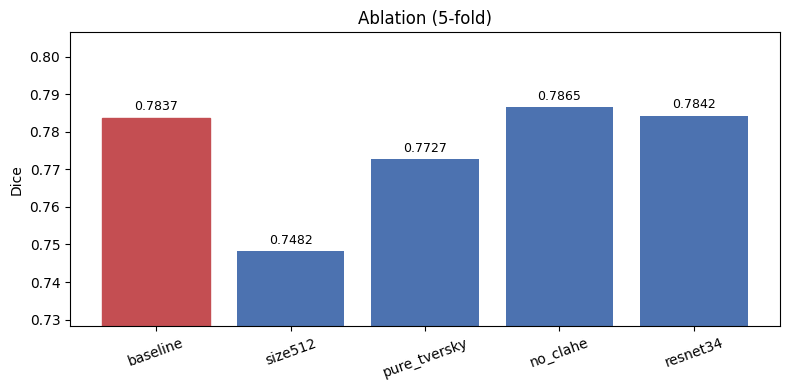

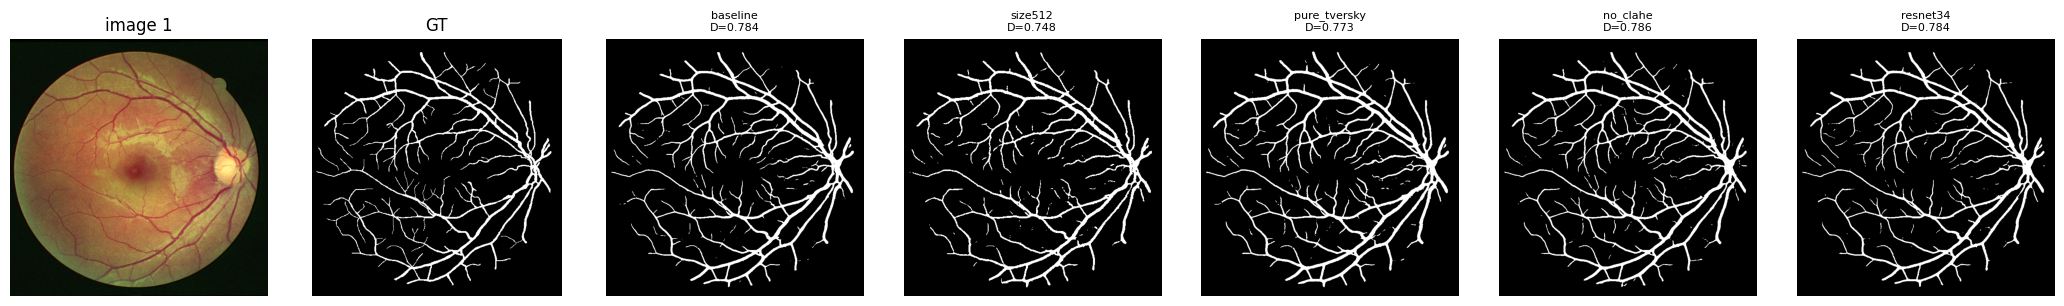

In [12]:
# ================= 消融实验 + 可视化 =================
import os, glob, random, time
import numpy as np
import torch
import torch.nn as nn
import cv2
import albumentations as A
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

ROOT     = "/kaggle/input/competitions/2026task-4/segmentation"
IMG_DIR  = os.path.join(ROOT, "train", "image")
LBL_DIR  = os.path.join(ROOT, "train", "label")
DEV      = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- 基础工具 ----------
def set_seed(s=42):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True

def list_names(d):
    return sorted(os.path.splitext(os.path.basename(p))[0] for p in glob.glob(os.path.join(d, "*")))

def read_img(path, clahe=True):
    img = cv2.cvtColor(cv2.imread(path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if clahe:
        g = img[:, :, 1]
        img = img.copy()
        img[:, :, 1] = cv2.createCLAHE(2.0, (8, 8)).apply(g)
    return img

def read_lbl(path):
    return (cv2.imread(path, cv2.IMREAD_GRAYSCALE) > 0).astype(np.uint8)

def tf(size):
    return A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5),
        A.Affine(scale=(0.95,1.05), translate_percent=(-0.03,0.03), rotate=(-15,15), p=0.5),
        A.RandomBrightnessContrast(p=0.5), A.ElasticTransform(alpha=1, sigma=50, p=0.1),
    ])

class DS(Dataset):
    def __init__(self, names, size, clahe, train):
        self.names, self.size, self.clahe, self.train = names, size, clahe, train
        self.t = tf(size) if train else A.Compose([A.Resize(size, size)])
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        ip = glob.glob(os.path.join(IMG_DIR, n + ".*"))[0]
        lp = glob.glob(os.path.join(LBL_DIR, n + ".*"))[0]
        o = self.t(image=read_img(ip, self.clahe), mask=read_lbl(lp))
        x = np.transpose(o["image"].astype(np.float32)/255.0, (2,0,1))
        y = o["mask"].astype(np.float32)[None]
        return torch.from_numpy(x), torch.from_numpy(y), n

bce = nn.BCEWithLogitsLoss()

def d_loss(p, t, eps=1e-6):
    p = torch.sigmoid(p)
    return 1 - (2*(p*t).sum((2,3)) + eps) / (p.sum((2,3)) + t.sum((2,3)) + eps).mean()

def tv_loss(p, t, a=0.3, b=0.8, eps=1e-6):
    p = torch.sigmoid(p)
    tp = (p*t).sum((2,3)); fp = (p*(1-t)).sum((2,3)); fn = ((1-p)*t).sum((2,3))
    return 1 - ((tp+eps)/(tp+a*fp+b*fn+eps)).mean()

def d_score(p, t, eps=1e-6):
    p = (torch.sigmoid(p) > 0.5).float()
    return ((2*(p*t).sum((2,3)) + eps) / (p.sum((2,3)) + t.sum((2,3)) + eps)).mean().item()

@torch.no_grad()
def predict_tta(model, x):
    model.eval()
    ps = []
    for mode in [0, 1, 2]:
        xx = x
        if mode == 1: xx = torch.flip(x, dims=[3])
        if mode == 2: xx = torch.flip(x, dims=[2])
        p = torch.sigmoid(model(xx))
        if mode == 1: p = torch.flip(p, dims=[3])
        if mode == 2: p = torch.flip(p, dims=[2])
        ps.append(p)
    return torch.stack(ps).mean(0)[0, 0].cpu().numpy()

# ---------- 单组消融 ----------
def ablate(name, size=768, batch=1, epochs=60, lr=5e-4,
           loss="tversky", clahe=True, encoder="resnet18", folds=5):
    set_seed()
    names = list_names(IMG_DIR)
    idx = np.arange(len(names)); rng = np.random.RandomState(42); rng.shuffle(idx)
    fs = np.array_split(idx, folds)
    fold_dices, fold_probs = [], {}
    t0 = time.time()
    for fi, vi in enumerate(fs):
        set_seed(42 + fi)
        ti = np.setdiff1d(np.arange(len(names)), vi)
        trl = DataLoader(DS([names[i] for i in ti], size, clahe, True),
                         batch_size=batch, shuffle=True, num_workers=2, drop_last=True)
        val = DataLoader(DS([names[i] for i in vi], size, clahe, False),
                         batch_size=1, num_workers=2)
        m = smp.Unet(encoder_name=encoder, encoder_weights="imagenet",
                     in_channels=3, classes=1).to(DEV)
        opt = AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
        sch = CosineAnnealingLR(opt, T_max=epochs)
        best = -1
        for ep in range(epochs):
            m.train()
            for x, y, _ in trl:
                x, y = x.to(DEV), y.to(DEV)
                lg = m(x)
                L = (bce(lg, y) + d_loss(lg, y)) if loss == "dice" else \
                    (0.3*bce(lg, y) + 0.7*tv_loss(lg, y)) if loss == "tversky" else tv_loss(lg, y)
                opt.zero_grad(); L.backward(); opt.step()
            sch.step()
            m.eval()
            with torch.no_grad():
                v = np.mean([d_score(m(x.to(DEV)), y.to(DEV)) for x, y, _ in val])
            if v > best: best = v
        fold_dices.append(best)
        # 保存该折验证图概率，用于可视化
        with torch.no_grad():
            for x, y, n in val:
                fold_probs[n[0]] = (predict_tta(m, x.to(DEV)), y[0,0].cpu().numpy())
    print(f"[{name}] Dice={np.mean(fold_dices):.4f}  各折={[f'{d:.3f}' for d in fold_dices]}  用时={(time.time()-t0)/60:.1f}min")
    return np.mean(fold_dices), fold_probs

# ---------- 跑 5 组 ----------
configs = [
    ("baseline",     dict()),
    ("size512",      dict(size=512, batch=2)),
    ("pure_tversky", dict(loss="pure_tversky")),
    ("no_clahe",     dict(clahe=False)),
    ("resnet34",     dict(encoder="resnet34")),
]

results = {}
all_probs = {}
for name, kw in configs:
    dice, probs = ablate(name, **kw)
    results[name] = dice
    all_probs[name] = probs

# ---------- 可视化 ----------
# 1) Dice 柱状图
plt.figure(figsize=(8, 4))
names_ = list(results.keys()); vals_ = [results[n] for n in names_]
bars = plt.bar(names_, vals_, color=["#4c72b0"]*len(names_))
bars[0].set_color("#c44e52")  # baseline 标红
for b, v in zip(bars, vals_):
    plt.text(b.get_x()+b.get_width()/2, v+0.002, f"{v:.4f}", ha="center", fontsize=9)
plt.ylabel("Dice"); plt.title("Ablation (5-fold)"); plt.ylim(min(vals_)-0.02, max(vals_)+0.02)
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

# 2) 每组的预测对比（取同一张验证图）
sample_name = list(all_probs["baseline"].keys())[0]
ip = glob.glob(os.path.join(IMG_DIR, sample_name + ".*"))[0]
lp = glob.glob(os.path.join(LBL_DIR, sample_name + ".*"))[0]
gt = read_lbl(lp)
img_show = cv2.resize(read_img(ip), (512, 512))

n_cols = 2 + len(configs)
plt.figure(figsize=(3*n_cols, 3))
plt.subplot(1, n_cols, 1); plt.imshow(img_show); plt.title(f"image {sample_name}"); plt.axis("off")
plt.subplot(1, n_cols, 2); plt.imshow(gt, cmap="gray"); plt.title("GT"); plt.axis("off")
for j, (name, _) in enumerate(configs):
    prob, _ = all_probs[name][sample_name]
    msk = (prob > 0.6).astype(np.uint8)  # 统一用最优阈值 0.6 显示
    plt.subplot(1, n_cols, 3+j); plt.imshow(msk, cmap="gray")
    plt.title(f"{name}\nD={results[name]:.3f}", fontsize=8); plt.axis("off")
plt.tight_layout(); plt.show()